In [1]:
pip install -U mplhep

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys
sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)
from sidm.tools import utilities #scaleout, sidm_processor, llpnanoaodschema
from sidm.studies.cosmicVeto import functions
utilities.set_plot_style()

In [3]:
ratio  = 6.616/62.061775847
# ratio = 1
channel_name = "base_ljIso"


samples = ["TTJets",
               "DYJetsToLL",
               "QCD",
               "Diboson",
              # "data"
              ]
folder_name = f"OutputFiles/{channel_name}"
sum_hist={}
for s in samples :
    if s == "data":
        list1 = functions.get_data_files()
        list1 = [x for x in list1 if "C" in x]
    else:
        list1 = functions.get_bg_file_names(s)
    sum_hist[s]= utilities.sum_hist(list1, folder_name)

    



In [4]:
sum_hist.keys()

dict_keys(['TTJets', 'DYJetsToLL', 'QCD', 'Diboson'])

In [5]:
from hist import intervals
histogram_name  = "muon_trkNumPixelHits"
binning =1j

import numpy as np
for s in samples:
    hist_sum = sum_hist[s]
    if s == "data":
        histogram =hist_sum[histogram_name][channel_name, ::binning]
    else:
        histogram = ratio * functions.isM(hist_sum[histogram_name][channel_name, ::binning])
    
    displaced =  histogram.values()[:3].sum()
    prompt=  histogram.values()[3:].sum()
    total = histogram.values().sum()
    effi = displaced/total
    displaced_sigma = histogram.variances()[:3].sum()
    total_sigma = histogram.variances().sum()

    num_counts_arr = np.array([displaced**2 / displaced_sigma])
    # print(num_counts_arr)
    denom_counts_arr = np.array([total**2 / total_sigma])
    # print(denom_counts_arr)
    effi_error = intervals.ratio_uncertainty(
        num_counts_arr,
        denom_counts_arr,
        uncertainty_type='efficiency')[0][0]
    print (f"{s}, displaced: {displaced}, prompt: {prompt}, Efficiency: {effi}, Efficiency_err: {effi_error}")

TTJets, displaced: 4705.685978474669, prompt: 68340.98038258054, Efficiency: 0.06442027012177935, Efficiency_err: 0.0005369035005785144
DYJetsToLL, displaced: 339515.6612740363, prompt: 6028791.979107352, Efficiency: 0.05331332599593182, Efficiency_err: 0.00012807639654906916
QCD, displaced: 82207.75893287134, prompt: 832469.8419286163, Efficiency: 0.08987621305632072, Efficiency_err: 0.0034731358635635146
Diboson, displaced: 648.516781817506, prompt: 11509.378232147701, Efficiency: 0.05334120594663674, Efficiency_err: 0.00034065655495386926


In [6]:
histogram_name  = "mu_lj_pfMu_max_trkNumPixelHits"
binning =1j
import numpy as np
for s in samples:
    hist_sum = sum_hist[s]
    if s == "data":
        histogram =hist_sum[histogram_name][channel_name, ::binning]
    else:
        histogram = ratio * functions.isM(hist_sum[histogram_name][channel_name, ::binning])
    
    displaced =  histogram.values()[:3].sum()
    prompt=  histogram.values()[3:].sum()
    ratio_ = displaced/prompt
    ratio_error = ratio * np.sqrt(1 / displaced + 1 / prompt)
    print (f"{s}, displaced: {displaced}, prompt: {prompt}, ratio: {ratio_}, ratio_err: {ratio_error}")

TTJets, displaced: 12.912368822572143, prompt: 353.86870232670685, ratio: 0.03648915187376726, ratio_err: 0.030203044142800246
DYJetsToLL, displaced: 1120.7683112560665, prompt: 16348.939278510159, ratio: 0.06855296800381777, ratio_err: 0.0032916329725106662
QCD, displaced: 1234.2881485627681, prompt: 29475.821365885215, ratio: 0.04187459725859619, ratio_err: 0.0030972106453016866
Diboson, displaced: 2.5856887263827493, prompt: 57.57581088599377, ratio: 0.0449092889286907, ratio_err: 0.06776765724307991


In [7]:
histogram_name  = "mu_lj_pfMu_min_trkNumPixelHits"
binning =1j
import numpy as np
for s in samples:
    hist_sum = sum_hist[s]
    if s == "data":
        histogram =hist_sum[histogram_name][channel_name, ::binning]
    else:
        histogram = ratio * functions.isM(hist_sum[histogram_name][channel_name, ::binning])
    
    displaced =  histogram.values()[:3].sum()
    prompt=  histogram.values()[3:].sum()
    ratio_ = displaced/prompt
    ratio_error = ratio * np.sqrt(1 / displaced + 1 / prompt)
    print (f"{s}, displaced: {displaced}, prompt: {prompt}, ratio: {ratio_}, ratio_err: {ratio_error}")

TTJets, displaced: 41.52896999692121, prompt: 325.2521011523577, ratio: 0.12768240343347642, ratio_err: 0.017566656940906908
DYJetsToLL, displaced: 2456.004036150776, prompt: 15013.703553615447, ratio: 0.16358415679250213, ratio_err: 0.0023203615468555885
QCD, displaced: 3716.605565192891, prompt: 26993.50394925509, ratio: 0.13768518426432202, ratio_err: 0.0018651300227366368
Diboson, displaced: 7.274125735232969, prompt: 52.88737387714354, ratio: 0.13753993064829875, ratio_err: 0.04215646842210127


In [8]:
#looking at the signal
channel_name = "base_ljIso"


samples = ["signal_2mu",
               "signal_4mu",
              ]
folder_name = f"OutputFiles/{channel_name}"
sum_hist_signal={}

S = [
'4Mu_500GeV_0p25GeV_0p04mm',
'4Mu_500GeV_0p25GeV_2p0mm',
'4Mu_500GeV_1p2GeV_0p19mm',
'4Mu_500GeV_1p2GeV_9p6mm',
'4Mu_500GeV_5p0GeV_0p8mm',
'4Mu_500GeV_5p0GeV_40p0mm',
'2Mu2E_500GeV_0p25GeV_0p04mm',
'2Mu2E_500GeV_0p25GeV_2p0mm',
'2Mu2E_500GeV_1p2GeV_0p19mm',
'2Mu2E_500GeV_1p2GeV_9p6mm',
'2Mu2E_500GeV_5p0GeV_0p8mm',
'2Mu2E_500GeV_5p0GeV_40p0mm',
]

for s in samples :
    output_signal = functions.load_output(s, channel_name)
    sum_hist_signal[s]= output_signal

for s in S:
    try:
        histogram = sum_hist_signal["signal_2mu"]["out"][s]["hists"][histogram_name][channel_name, :]
    except:
        histogram = sum_hist_signal["signal_4mu"]["out"][s]["hists"][histogram_name][channel_name, :]
    displaced =  histogram.values()[:3].sum()
    disp_var =  histogram.variances()[:3].sum()
    prompt=  histogram.values()[3:].sum()
    prompt_var =  histogram.variances()[3:].sum()
    ratio_ = displaced/prompt
    ratio_error = ratio * np.sqrt( disp_var/ displaced**2 + prompt_var/ prompt**2)
    label = functions.get_signal_label(s)
    print (f"{label}, displaced: {displaced}, prompt: {prompt}, ratio: {ratio_}, ratio_err: {ratio_error}")





4$\mu$, 500GeV, 0.25GeV, 3cm, displaced: 44.397392400860554, prompt: 47.43357102575828, ratio: 0.9359909330198023, ratio_err: 0.0003528308721354684
4$\mu$, 500GeV, 0.25GeV, 150cm, displaced: 18.99113721968024, prompt: 2.2866261617455166, ratio: 8.305309165702532, ratio_err: 0.0012793721920598463
4$\mu$, 500GeV, 1.2GeV, 3cm, displaced: 23.013061163801467, prompt: 67.68062143717543, ratio: 0.3400243773642556, ratio_err: 0.0003856718671257134
4$\mu$, 500GeV, 1.2GeV, 150cm, displaced: 16.522958510089666, prompt: 2.927954330574721, ratio: 5.643174942160527, ratio_err: 0.0010910706319758197
4$\mu$, 500GeV, 5.0GeV, 3cm, displaced: 23.202896825852804, prompt: 65.84612747479696, ratio: 0.35238058357697444, ratio_err: 0.0004109672662873823
4$\mu$, 500GeV, 5.0GeV, 150cm, displaced: 15.41392476222245, prompt: 2.8593893908546306, ratio: 5.390635081574339, ratio_err: 0.0011143676029496358
2$\mu2e$, 500GeV, 0.25GeV, 3cm, displaced: 14.83837039466016, prompt: 15.893677564221434, ratio: 0.9336020775999

In [9]:
import matplotlib.pyplot as plt

4$\mu$, 500GeV, 0.25GeV, 3cm, displaced: 44.397392400860554, prompt: 47.43357102575828, ratio: 0.9359909330198023, ratio_err: 0.0003528308721354684
4$\mu$, 500GeV, 0.25GeV, 150cm, displaced: 18.99113721968024, prompt: 2.2866261617455166, ratio: 8.305309165702532, ratio_err: 0.0012793721920598463
4$\mu$, 500GeV, 1.2GeV, 3cm, displaced: 23.013061163801467, prompt: 67.68062143717543, ratio: 0.3400243773642556, ratio_err: 0.0003856718671257134
4$\mu$, 500GeV, 1.2GeV, 150cm, displaced: 16.522958510089666, prompt: 2.927954330574721, ratio: 5.643174942160527, ratio_err: 0.0010910706319758197
4$\mu$, 500GeV, 5.0GeV, 3cm, displaced: 23.202896825852804, prompt: 65.84612747479696, ratio: 0.35238058357697444, ratio_err: 0.0004109672662873823
4$\mu$, 500GeV, 5.0GeV, 150cm, displaced: 15.41392476222245, prompt: 2.8593893908546306, ratio: 5.390635081574339, ratio_err: 0.0011143676029496358
2$\mu2e$, 500GeV, 0.25GeV, 3cm, displaced: 14.83837039466016, prompt: 15.893677564221434, ratio: 0.9336020775999

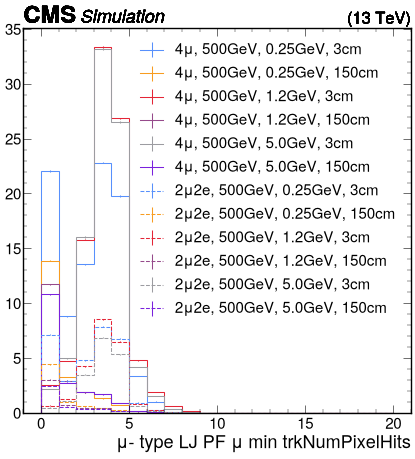

In [10]:
histogram_name  = "mu_lj_pfMu_min_trkNumPixelHits"
for s in S:
    label = functions.get_signal_label(s)
    try:
        histogram = sum_hist_signal["signal_2mu"]["out"][s]["hists"][histogram_name][channel_name, :]
        utilities.plot(histogram, linestyle = "--", label=label)
        
    except:
        histogram = sum_hist_signal["signal_4mu"]["out"][s]["hists"][histogram_name][channel_name, :]
        utilities.plot(histogram,label=label)
    displaced =  histogram.values()[:3].sum()
    disp_var =  histogram.variances()[:3].sum()
    prompt=  histogram.values()[3:].sum()
    prompt_var =  histogram.variances()[3:].sum()
    ratio_ = displaced/prompt
    ratio_error = ratio * np.sqrt( disp_var/ displaced**2 + prompt_var/ prompt**2)
    
    print (f"{label}, displaced: {displaced}, prompt: {prompt}, ratio: {ratio_}, ratio_err: {ratio_error}")
plt.legend()


4$\mu$, 500GeV, 0.25GeV, 3cm, displaced: 18.554704057169147, prompt: 73.27625936944969, ratio: 0.25321576478977537, ratio_err: 0.00043911630075892555
4$\mu$, 500GeV, 0.25GeV, 150cm, displaced: 17.656904522911645, prompt: 3.6208588585141115, ratio: 4.876440980678682, ratio_err: 0.001054403634508823
4$\mu$, 500GeV, 1.2GeV, 3cm, displaced: 16.806698344589677, prompt: 73.88698425638722, ratio: 0.22746493869976575, ratio_err: 0.00043192878933004744
4$\mu$, 500GeV, 1.2GeV, 150cm, displaced: 16.104009358678013, prompt: 3.3469034819863737, ratio: 4.811614510353418, ratio_err: 0.0010336900126945382
4$\mu$, 500GeV, 5.0GeV, 3cm, displaced: 14.790421996149234, prompt: 74.25860230450053, ratio: 0.1991745270871176, ratio_err: 0.00048470755296343125
4$\mu$, 500GeV, 5.0GeV, 150cm, displaced: 14.814056548231747, prompt: 3.459257604845334, ratio: 4.282438095238096, ratio_err: 0.001033459102128371
2$\mu2e$, 500GeV, 0.25GeV, 3cm, displaced: 6.6414121082634665, prompt: 24.090635850618128, ratio: 0.27568438

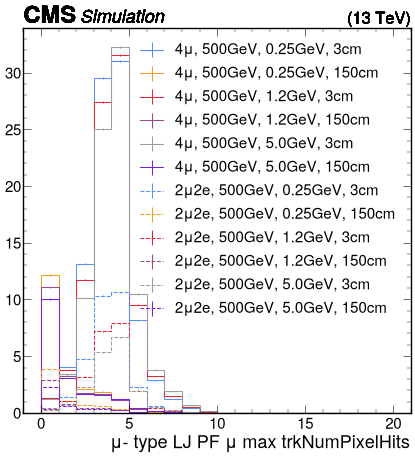

In [11]:
histogram_name  = "mu_lj_pfMu_max_trkNumPixelHits"
for s in S:
    label = functions.get_signal_label(s)
    try:
        histogram = sum_hist_signal["signal_2mu"]["out"][s]["hists"][histogram_name][channel_name, :]
        utilities.plot(histogram, linestyle = "--", label=label)
        
    except:
        histogram = sum_hist_signal["signal_4mu"]["out"][s]["hists"][histogram_name][channel_name, :]
        utilities.plot(histogram,label=label)
    displaced =  histogram.values()[:3].sum()
    disp_var =  histogram.variances()[:3].sum()
    prompt=  histogram.values()[3:].sum()
    prompt_var =  histogram.variances()[3:].sum()
    ratio_ = displaced/prompt
    ratio_error = ratio * np.sqrt( (disp_var/ displaced**2) + (prompt_var/ prompt**2))
    
    print (f"{label}, displaced: {displaced}, prompt: {prompt}, ratio: {ratio_}, ratio_err: {ratio_error}")
plt.legend()
